# Multimodality, tempering and misleading warm starts

Eight replicas help explore separated modes, with an explicit work cost. Starting all chains near one mode can make local diagnostics misleading.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
ROOT=Path.cwd()
if ROOT.name == "notebooks": ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
torch.set_num_threads(1)
from sampling_lab.targets import load_target
from sampling_lab.artifacts import sha256
def read(path): return json.loads((ROOT/path).read_text())
def numeric(name): return np.load(ROOT/"assets/source_data"/(name+".npz"),allow_pickle=False)
%matplotlib inline


## Independent implementation check

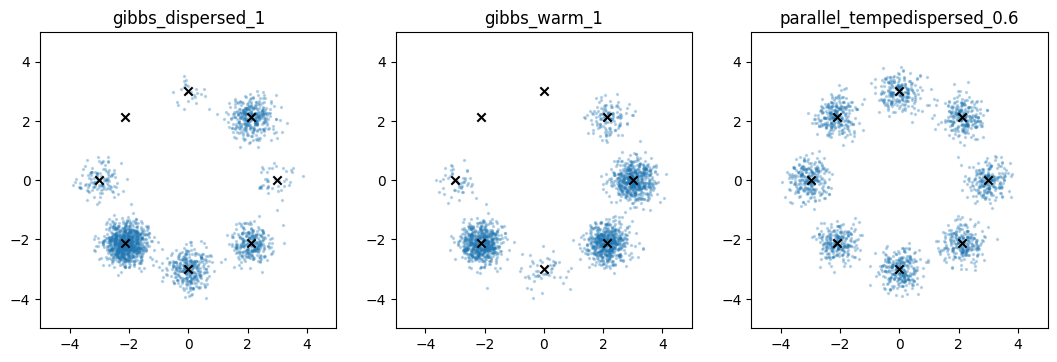

,protocol,visited_modes,max_Rhat,screen
0,ring_gibbs_dispersed_1,7,1.731181,False
1,ring_gibbs_warm_1,6,1.682538,False
2,ring_parallel_tempering_dispersed_0.6,8,1.004993,True


In [2]:
target=load_target("ring");names=["ring_gibbs_dispersed_1","ring_gibbs_warm_1","ring_parallel_tempering_dispersed_0.6"]
fig,axes=plt.subplots(1,3,figsize=(13,4));rows=[]
for ax,name in zip(axes,names):
 values=numeric(name)["samples"].reshape(-1,2)
 label=np.argmin(((values[:,None]-target.centers)**2).sum(-1),axis=1)
 counts=np.bincount(label,minlength=8)
 m=read("results/reference/sampling/"+name+"/metrics.json")
 rows.append({"protocol":name,"visited_modes":int((counts>0).sum()),"max_Rhat":max(m["diagnostics"]["rank_rhat"]),"screen":m["diagnostics"]["convergence_flag"]})
 ax.scatter(*values[::4].T,s=2,alpha=.25);ax.scatter(*target.centers.T,marker="x",c="black");ax.set(title=name.replace("ring_",""),aspect="equal",xlim=(-5,5),ylim=(-5,5))
plt.show();display(pd.DataFrame(rows))

## Inspect measured evidence

In [3]:
m=read("results/reference/sampling/ring_parallel_tempering_dispersed_0.6/metrics.json")
print("Per-ladder swap acceptance",m["swap_acceptance"])
assert len(m["swap_acceptance"])==4
print("Only the cold replica estimates the target; eight replicas have unequal work versus single-chain MH.")

Per-ladder swap acceptance [0.8046666666666666, 0.8071428571428572, 0.8034285714285714, 0.8063809523809524]
Only the cold replica estimates the target; eight replicas have unequal work versus single-chain MH.


## Interpretation and next step

Read the [theory](../docs/theory.md), [diagnostic scope](../docs/diagnostics.md), and [data protocol](../docs/data_and_protocols.md). Change one declared preset in a separate output directory; keep warmup, test evaluation and model selection distinct. The [interactive explorer](../docs/explorer.html) exposes the complete recorded comparisons.